In [76]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lu_factor, lu_solve

np.random.seed(42)

In [77]:

import matplotlib as mpl

# ---- STILE PAPER ----
mpl.rcParams.update({

    # Usa font LaTeX (coerente con paper)
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],

    # Dimensioni testo (standard journal)
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,

    # Spessori ottimizzati per stampa
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    # Tick dentro (stile PRL/JCP)
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Griglia molto leggera
    "grid.linestyle": ":",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,

    # Legenda minimale
    "legend.frameon": False,
})

# Test generazione dataset di funzioni

Genero un dataset di funzioni usando "generate_random_f_from_white_noise". In seguito tratto le funzioni generate come vettori e calcolo la matrice di correlazione.

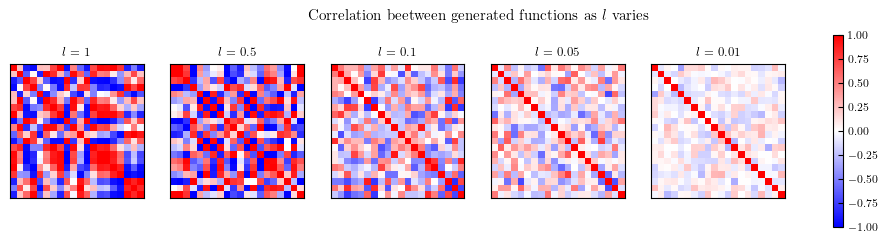

In [78]:
from functions_generator import *

f_dataset_size = 20
nt = 1000
t_array = np.linspace(0,1,nt)

# Dataset di funzioni dove ogni colonna rappresenta una funzione random su una gliglia temporale
# rappresentata dalle righe. Il dataset è dunque composto da vettori nt dimensionali.
f_dataset = np.zeros(shape=(nt,f_dataset_size))

dt = t_array[1] - t_array[0]   

fig, axes = plt.subplots(1,5,figsize=(12.5,2.5))   
index_ax = 0

for l in [1,0.5,0.1,0.05,0.01]:
    
    for index in range(f_dataset_size):
        f_dataset[:,index] = generate_random_f_from_white_noise(t_array, l=l)

    # Verifico l'indipendenza tra le colonne
    f_corr = np.corrcoef(f_dataset, rowvar=False)

    im = axes[index_ax].imshow(f_corr, cmap='bwr', vmin=-1, vmax=1)
    axes[index_ax].set_title(rf"$l$ = {l}")
    axes[index_ax].set_xticks([])
    axes[index_ax].set_yticks([])
    index_ax=index_ax+1

fig.colorbar(im, ax=axes.ravel().tolist())
fig.suptitle(r"Correlation beetween generated functions as $l$ varies")
plt.savefig("assets/dataset_function_correlations.pdf")
plt.show()

Il filtro passa basso nello spazio di fourier assieme alla continuità delle funzioni introduce una correlazione nel dataset. Il filtro proietta le funzioni su un sottospazio di dimensione sempre più piccola al diminuire della sigma_filtro. Questo si vede dalla diminuzione della correlazione con l'aumento della sigma del filtro gaussiano.

Text(0.5, 0, '$\\tau$')

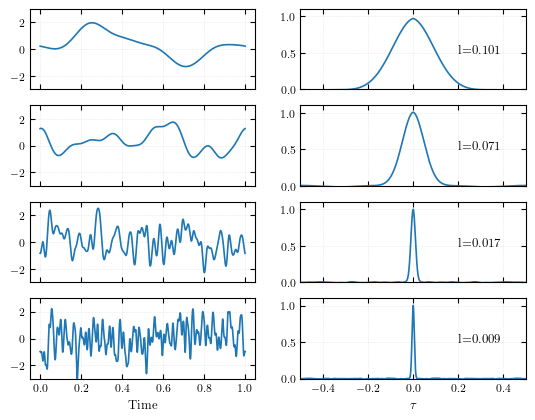

In [79]:
from scipy import signal

Tf = 1
nt = 30000
t_array = np.linspace(0,Tf,nt)
sigma = 1
Nf = 1000

# Array di coorelazioni temporali
l_array = [0.1, 0.05, 0.01, 0.005]

fig, axes = plt.subplots(4,2, sharex="col")

index_axes = 0

for l in l_array:
    
    f_array = np.ndarray(shape=(Nf, nt))
    var_array = np.ndarray(Nf)
    correlations_array =  np.ndarray(shape=(Nf, nt))

    for i in range(Nf):
        f_array[i,:] = generate_random_f_from_white_noise(t_array, l = l, sigma = sigma)
        var_array[i] = np.var(f_array[i])
        correlations_array[i,:] = signal.correlate(f_array[i,:], f_array[i,:], mode="same", method="fft") / nt
    
    variance_correlation = np.var(np.mean(correlations_array, axis=0))

    lag_array = t_array - Tf/2

    axes[index_axes][1].plot(lag_array, np.mean(correlations_array, axis=0))
    axes[index_axes][1].grid()
    axes[index_axes][1].set_ylim([0,1.1])
    axes[index_axes][1].set_xlim([- Tf/2,Tf/2])

    # Plot estimate of l
    axes[index_axes][1].text(0.2,0.5,f"l={variance_correlation:.3f}")

    axes[index_axes][0].plot(t_array, f_array[0,:])
    axes[index_axes][0].grid()
    axes[index_axes][0].set_ylim([-3,3])

    index_axes = index_axes + 1

axes[3][0].set_xlabel("Time")
axes[3][1].set_xlabel(r"$\tau$")

In [80]:
# Plot complessità computazionale
import time

gaus_times = []
white_times = []

nt_array = np.linspace(100,200,20, dtype=int)

for nt in nt_array:
    
    print(nt)
    
    t_array = np.linspace(0,1,nt)
    
    start = time.time()
    for _ in range(5):
        generate_random_f_from_Gaussian_Process(t_array, l = l, sigma = sigma)
    end = time.time()
    gaus_times.append((end-start)/10)

    for _ in range(5):
        start = time.time()
        generate_random_f_from_white_noise(t_array, l = l, sigma = sigma)
        end = time.time()
    white_times.append((end-start)/10)

100
105
110
115
121
126
131
136
142
147
152
157
163
168
173
178
184
189
194
200


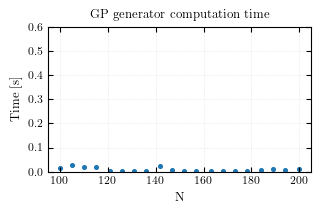

In [81]:
plt.figure(figsize=(3.4, 2.2))
plt.scatter(nt_array,gaus_times,s=7)
plt.xlabel("N")
plt.ylabel("Time [s]")
plt.title("GP generator computation time")
plt.tight_layout()
plt.ylim([0,0.6])
plt.grid()
plt.savefig("assets/crescita_powerlaw_generatore_f.pdf")
plt.show()